# Практическая работа №1

---

**Описание датасета:**

* Сслыка на датасет: *https://www.kaggle.com/datasets/nudratabbas/ai-worker-burnout-and-attrition-risk-dataset*

* Содержит небольшую выборку (1500 элементов) из 20 признаков + 1 целевой. Исследуемые признаки несут информацию об использовании ИИ-инструментов в работе. Целевой признак содержит метку класса, отражающего вероятность выгорания сотрудника (Low, Medium, High).

* Ставится задача классификации: обучить модель предсказывать вероятность выгорания на работе на основе собирательных данных о сотруднике.

**Формулировка задачи:**

*Выявить зависимости в числовых данных. Сформулировать выводы и рекоммендации для дальнейшего обучения модели машинного обучения*

**Примечание:**

*Работа выполнялась на ПК в IDE VS Code с предварительно загруженными в локальное окружение необходимыми библиотеками (не в среде Google Colab)*

---

In [2]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import numpy as np
import pandas as pd

from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.ticker import FormatStrFormatter

import os

# Краткий обзор (Overview)

In [3]:
df = pd.read_csv(f'{os.getcwd()}/content/ai_worker_burnout_attrition_2026.csv')
df.info() # посмотрим сколько признаков, есть ли пропущенные, а также их тип, распознан ли он правильно

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   employee_id                     1500 non-null   str    
 1   job_role                        1500 non-null   str    
 2   years_experience                1500 non-null   int64  
 3   education_level                 1500 non-null   str    
 4   country                         1500 non-null   str    
 5   industry                        1500 non-null   str    
 6   company_size                    1500 non-null   str    
 7   remote_work_type                1500 non-null   str    
 8   team_size                       1500 non-null   int64  
 9   salary_usd_k                    1500 non-null   int64  
 10  primary_ai_tool                 1500 non-null   str    
 11  ai_tools_used_per_day           1500 non-null   int64  
 12  hours_with_ai_assistance_daily  1500 non-null

Таким образом, датасет содержит 10 числовых признаков и 11 номинальных (включая целевой - `attrition_risk`)

In [62]:
df.describe() 

,years_experience,team_size,salary_usd_k,ai_tools_used_per_day,hours_with_ai_assistance_daily,ai_replaces_my_tasks_pct,weekly_ai_upskilling_hrs,productivity_score,burnout_score,job_satisfaction_1_5
count,1500.000000,1500.000000,1500.000000,1500.00000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,9.947333,24.812667,140.734000,4.05600,4.233733,41.248667,4.985533,57.543333,50.057333,3.334733
std,5.460932,13.682582,59.717429,1.97403,2.148387,21.658214,2.913933,10.726952,11.437771,0.636692
min,1.000000,2.000000,40.000000,1.00000,0.500000,5.000000,0.000000,25.000000,16.000000,1.300000
25%,5.000000,13.000000,91.000000,2.00000,2.400000,22.750000,2.400000,50.000000,42.000000,2.900000
50%,10.000000,25.000000,139.000000,4.00000,4.200000,40.000000,5.000000,57.000000,50.000000,3.300000
75%,15.000000,36.000000,190.000000,6.00000,6.100000,60.000000,7.500000,65.000000,58.000000,3.800000
max,19.000000,49.000000,249.000000,7.00000,8.000000,79.000000,10.000000,95.000000,86.000000,5.000000


In [63]:
df.head(5)

,employee_id,job_role,years_experience,education_level,country,industry,company_size,remote_work_type,team_size,salary_usd_k,...,ai_tools_used_per_day,hours_with_ai_assistance_daily,ai_replaces_my_tasks_pct,ai_adoption_stage,weekly_ai_upskilling_hrs,productivity_score,burnout_score,job_satisfaction_1_5,fear_of_ai_replacement,attrition_risk
0,EMP0001,Data Analyst,7,PhD,India,Healthtech,Large (1000-5000),Fully Remote,8,184,...,1,0.6,37,Experimenting,4.9,59,58,3.0,Low,Medium
1,EMP0002,DevOps Engineer,3,Self-taught,Canada,Fintech,Large (1000-5000),Hybrid,42,51,...,3,0.6,78,Experimenting,6.6,64,47,3.6,Medium,Medium
2,EMP0003,Prompt Engineer,3,PhD,India,Automotive,Startup (<50),Hybrid,37,185,...,4,4.0,23,Optimizing,5.8,50,37,4.6,High,Medium
3,EMP0004,Backend Engineer,18,Master,Germany,Media,Mid (200-1000),Fully Remote,8,131,...,5,4.2,75,Integrating,1.4,77,67,3.0,Low,Medium
4,EMP0005,AI Researcher,5,Bachelor,India,E-commerce,Small (50-200),Fully Remote,21,99,...,7,0.7,61,Experimenting,1.6,58,54,3.6,Medium,Medium


# Анализ числовых (вещественных) параметров

In [76]:
NUMERIC_FEATURES = [
    'years_experience', 'team_size', 'salary_usd_k', 
    'ai_tools_used_per_day', 'hours_with_ai_assistance_daily',
    'ai_replaces_my_tasks_pct', 'weekly_ai_upskilling_hrs',
    'productivity_score', 'burnout_score', 'job_satisfaction_1_5'
]

TARGET_FEATURE = "attrition_risk"

print(f"Количество числовых признаков: {len(NUMERIC_FEATURES)}")

Количество числовых признаков: 10


## Одномерный анализ

In [65]:
def plot_feature_histogram(ax, df, feature, bins=30, y_scale='linear'):
    n_bins = min(bins, df[feature].nunique())
    
    ax.set_yscale(y_scale)
    ax.hist(df[feature].dropna(), bins=n_bins, edgecolor='black', alpha=0.7)
    ax.set_title(feature, fontsize=12)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.grid(True, linestyle='--', alpha=0.3)

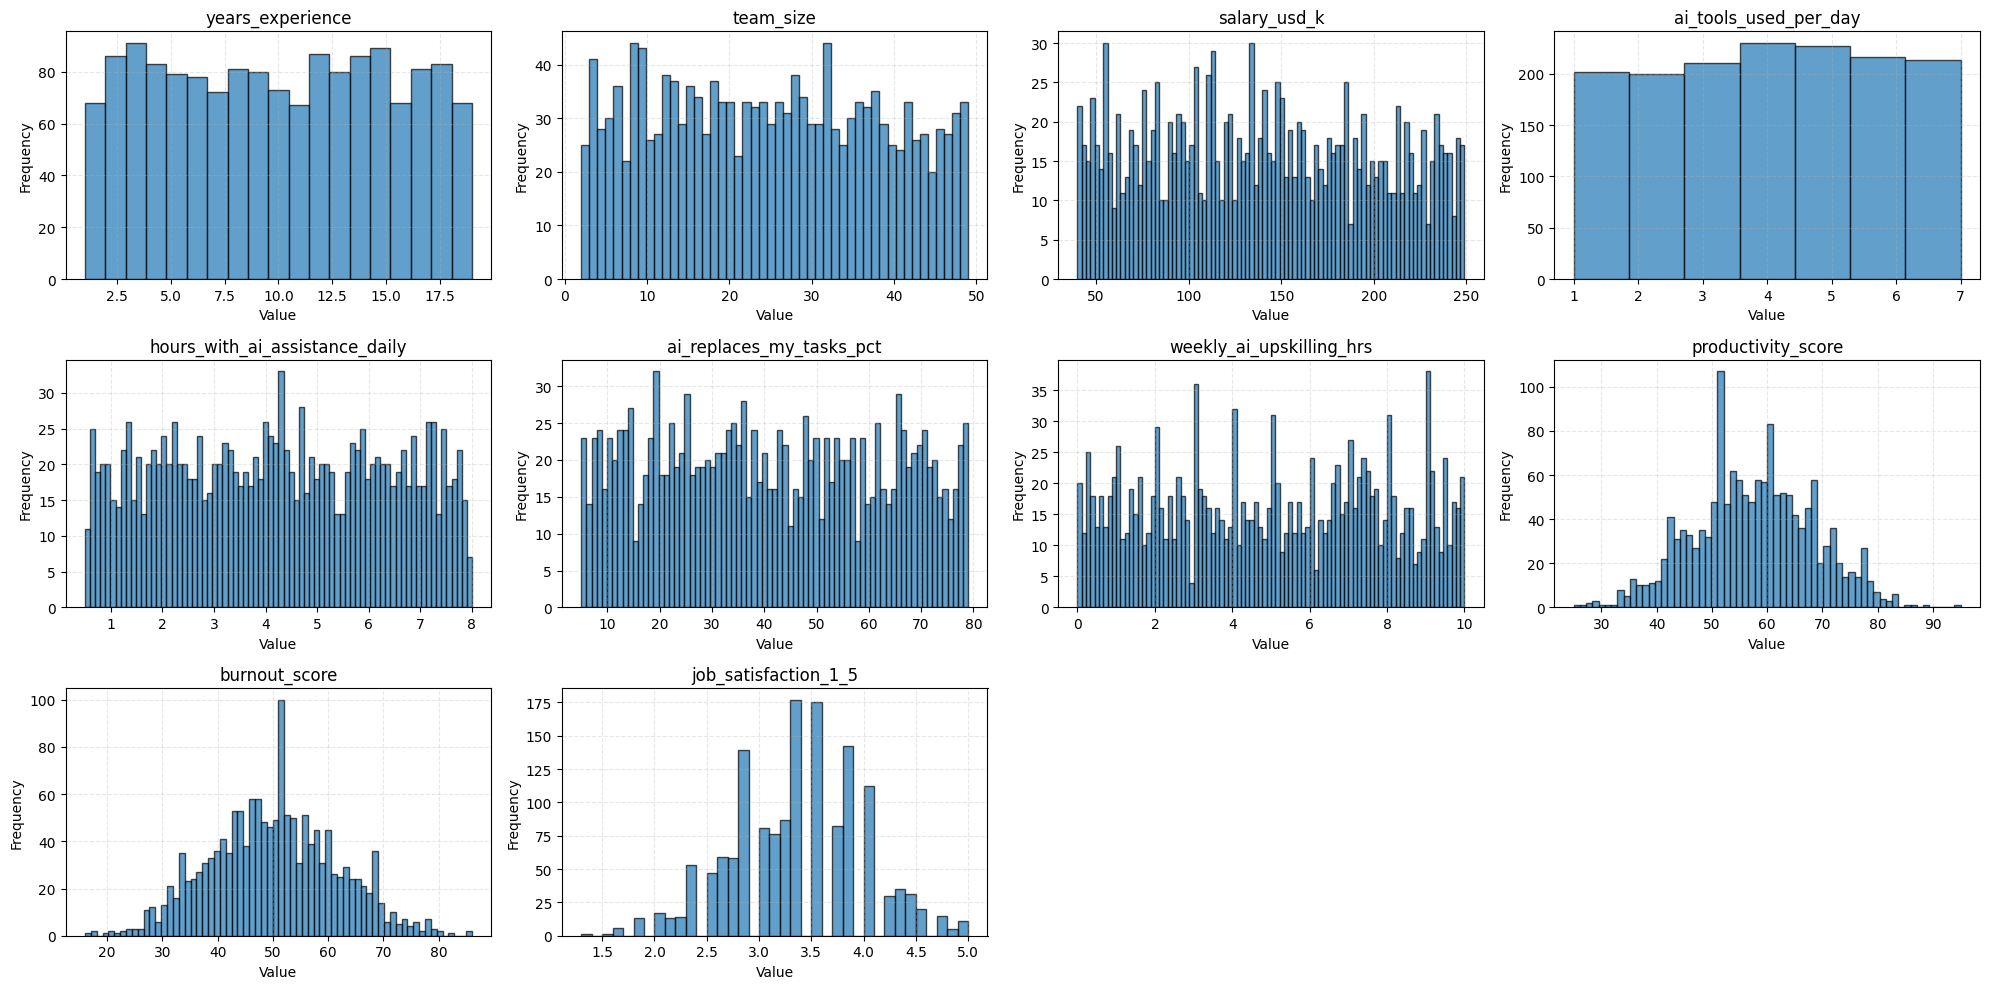

In [66]:
n_features = len(NUMERIC_FEATURES)

fig, axes = plt.subplots(3, 4, figsize=(20, 10))
axes = axes.flatten() if n_features > 1 else [axes]

for idx, feature in enumerate(NUMERIC_FEATURES):
    plot_feature_histogram(axes[idx], df, feature, bins=90, y_scale='linear')
for idx in range(n_features, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

Согласно изображению, можно выделить два основных типа распределений: нормальное (`productivity_score`, `burnout_score`, `job_satisfaction_1_5`) и равномерное (остальные).

In [67]:
def plot_boxplots(df, columns, figsize=(12, 6), rotation=45):
    n_cols = len(columns)
    fig, axes = plt.subplots(1, n_cols, figsize=figsize)
    
    if n_cols == 1:
        axes = [axes]
    
    for ax, col in zip(axes, columns):
        ax.boxplot(df[col].dropna(), patch_artist=True, 
                   boxprops=dict(facecolor='#AEC7E8'),
                   medianprops=dict(color='red', linewidth=2))
        ax.set_title(col, fontsize=12)
        ax.set_ylabel('Value')
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        ax.tick_params(axis='x', rotation=rotation)

    plt.tight_layout()
    plt.show()

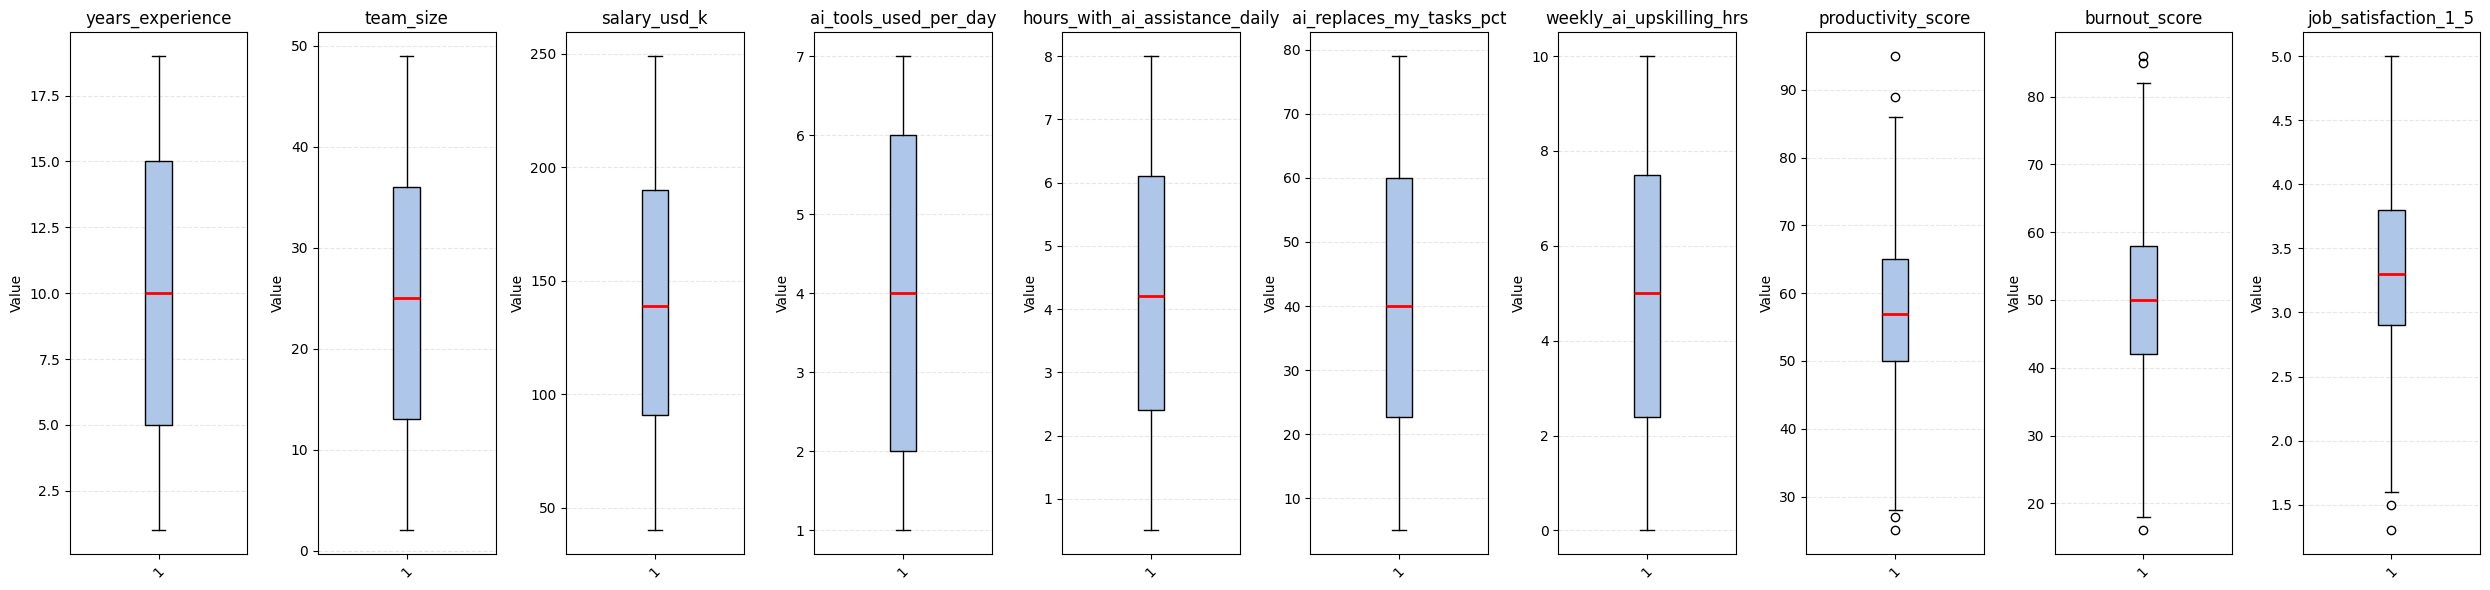

In [68]:
plot_boxplots(df, NUMERIC_FEATURES, figsize=(25, 6))

Полученные графики подтверждают и дополняют выводы из гистограмм:

* `productivity_score`, `burnout_score`, `job_satisfaction_1_5` — ящики симметричны относительно медианы, усы примерно равной длины → соответствует нормальному/близкому к нормальному распределению на гистограммах. Выбросы есть, но их немного.

* `years_experience`, `team_size`, `ai_tools_used_per_day`, ... -  длинные ящики (большой IQR), усы занимают почти весь диапазон, выбросов мало или нет → соответствует равномерному распределению, где данные "размазаны" по всему диапазону без концентрации вокруг центра.

In [69]:
def plot_class_distribution(df, column_name, figsize=(6, 4), rotation=30):
    class_values = df[column_name].unique()
    counts = [df[df[column_name] == val].shape[0] for val in class_values]
    
    fig, ax = plt.subplots(figsize=figsize)
    plt.xticks(rotation=rotation)
    plt.suptitle(f'Признак {column_name}', fontsize=16, y=0.97)
    ax.bar(class_values, counts, width=0.7)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

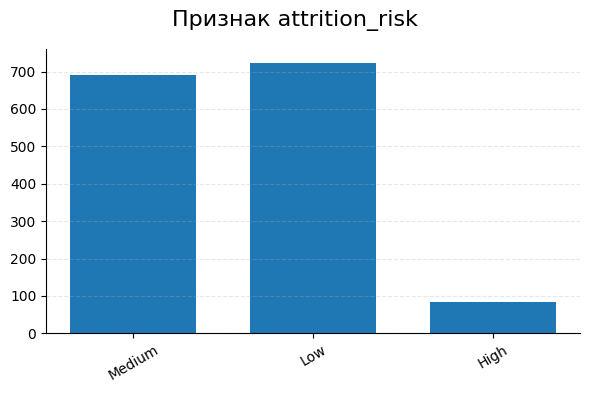

In [70]:
plot_class_distribution(df, TARGET_FEATURE)

Видно, что присутствует дисбаланс классов, что может сказаться на склонности дальнейшей модели машинного обучения отдавать препочтение в предсказании первым классам `Low` и `Medium`. Таким образом, при дальнейшей оценки модели следует отдавать использовать метрики оценки для каждого из классов в отдельности - в частности, для класса `High`. При необходимости, для повышения качества обучения можно будет использовать аугментацию данных для класса `High`, или же применить class weights при обучении

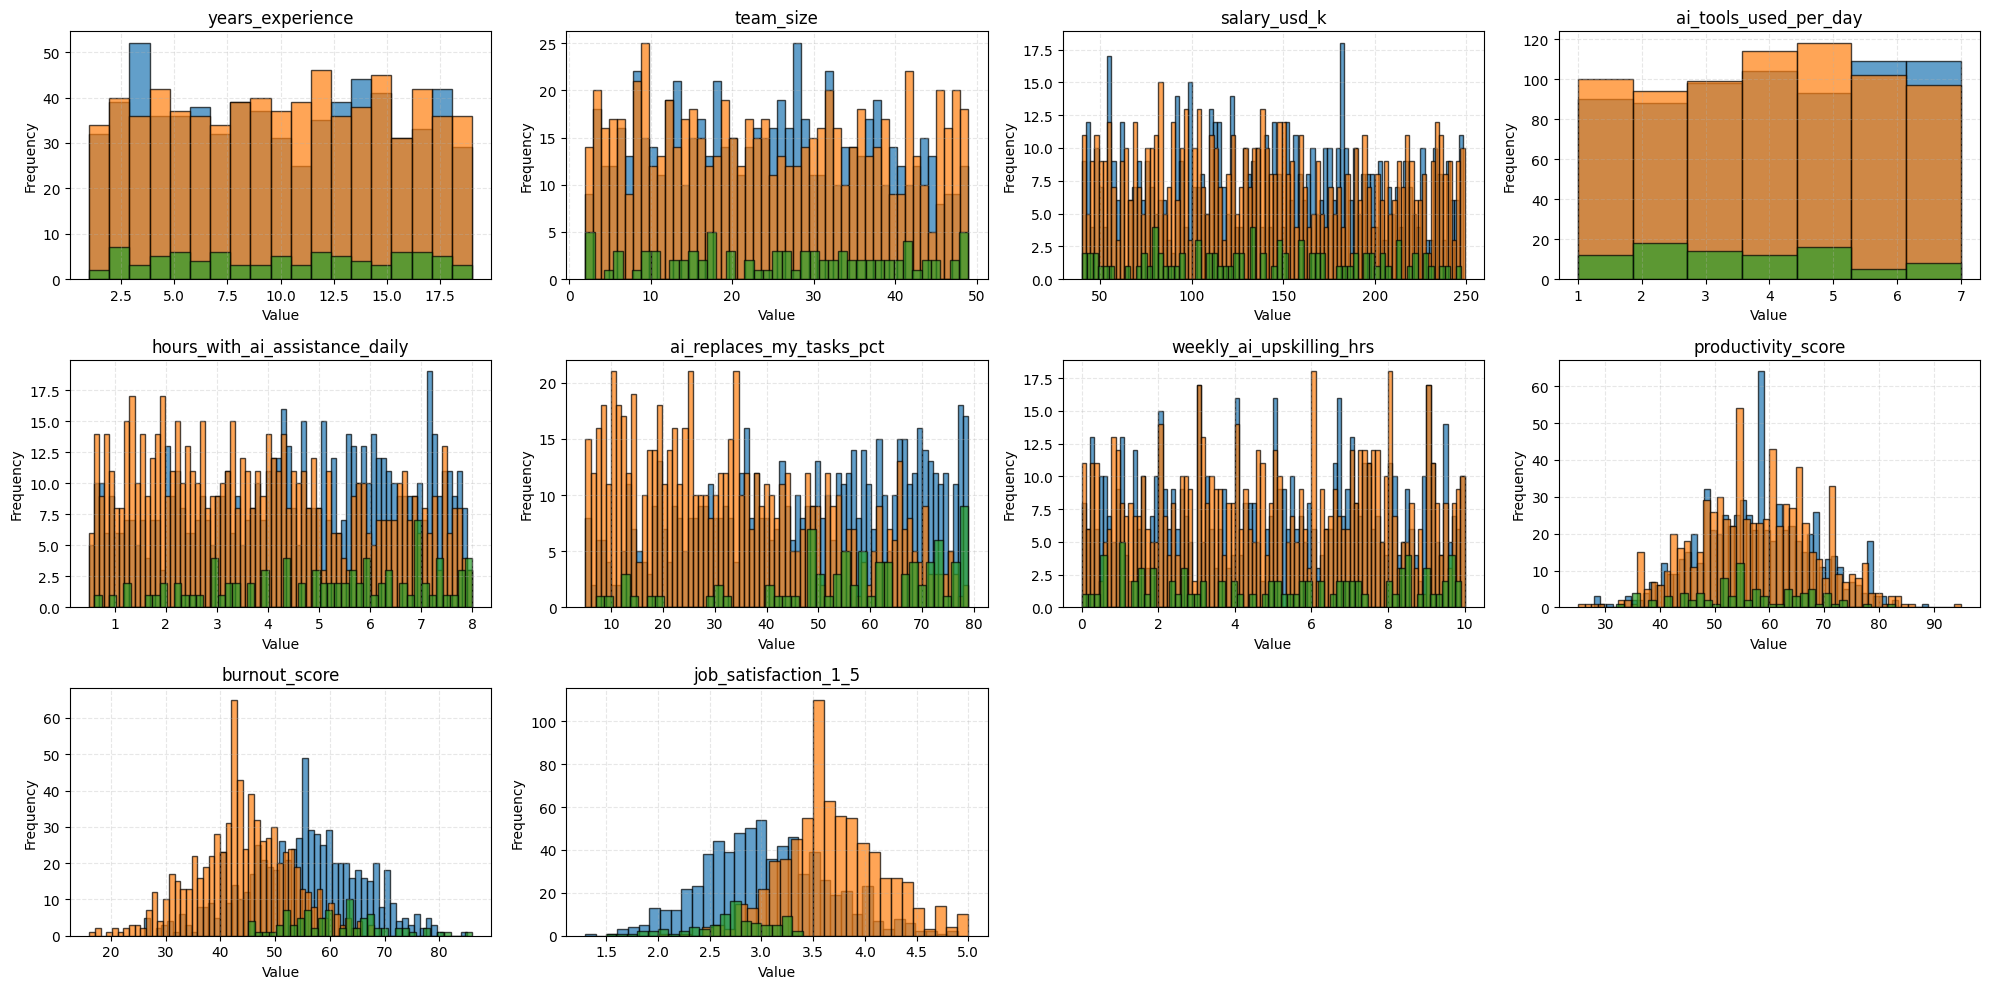

In [71]:
class_values = df[TARGET_FEATURE].unique()
n_features = len(NUMERIC_FEATURES)

fig, axes = plt.subplots(3, 4, figsize=(20, 10))
axes = axes.flatten() if n_features > 1 else [axes]

for class_value in class_values:
    class_value_df = df[df[TARGET_FEATURE] == class_value]
    for idx, feature in enumerate(NUMERIC_FEATURES):
        plot_feature_histogram(axes[idx], class_value_df, feature, bins=90, y_scale='linear')

for idx in range(n_features, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

Гистограммы вышли весьма информативными - можно выделить несколько ключевых наблюдений:

* Можно выделить __слабые предикаты__ (признаки, влияние которых на точность модели будет меньше, чем у остальных). Оценить это можно, если все три класса перекрываются и формы их распределений схожи. Слабыми предикатами, как будто бы, являются `years_experience`, `team_size`, `salary_usd_k`.

* В то же время, сразу видны и __хорошие предикторы__: `burnout_score`, `job_satisfaction_1_5` (пики распределений смещены, амплитуда также различна)

Можно заметить один интересный паттерн: у признака `ai_replaces_my_tasks_pct` класс `High` (зеленый) имеет больше записей в диапазоне 50-80%, что может указывать на связь между заменой задач ИИ и риском увольнения

## Двумерный анализ

Для начала построим матрицу корреляции. И сначала достаточно бездумно построим матрицу для всех параметров. В целом, такой диаграммы скорее всего хватит для анализа в моей случае, т.к. числовых признаков всего 10.

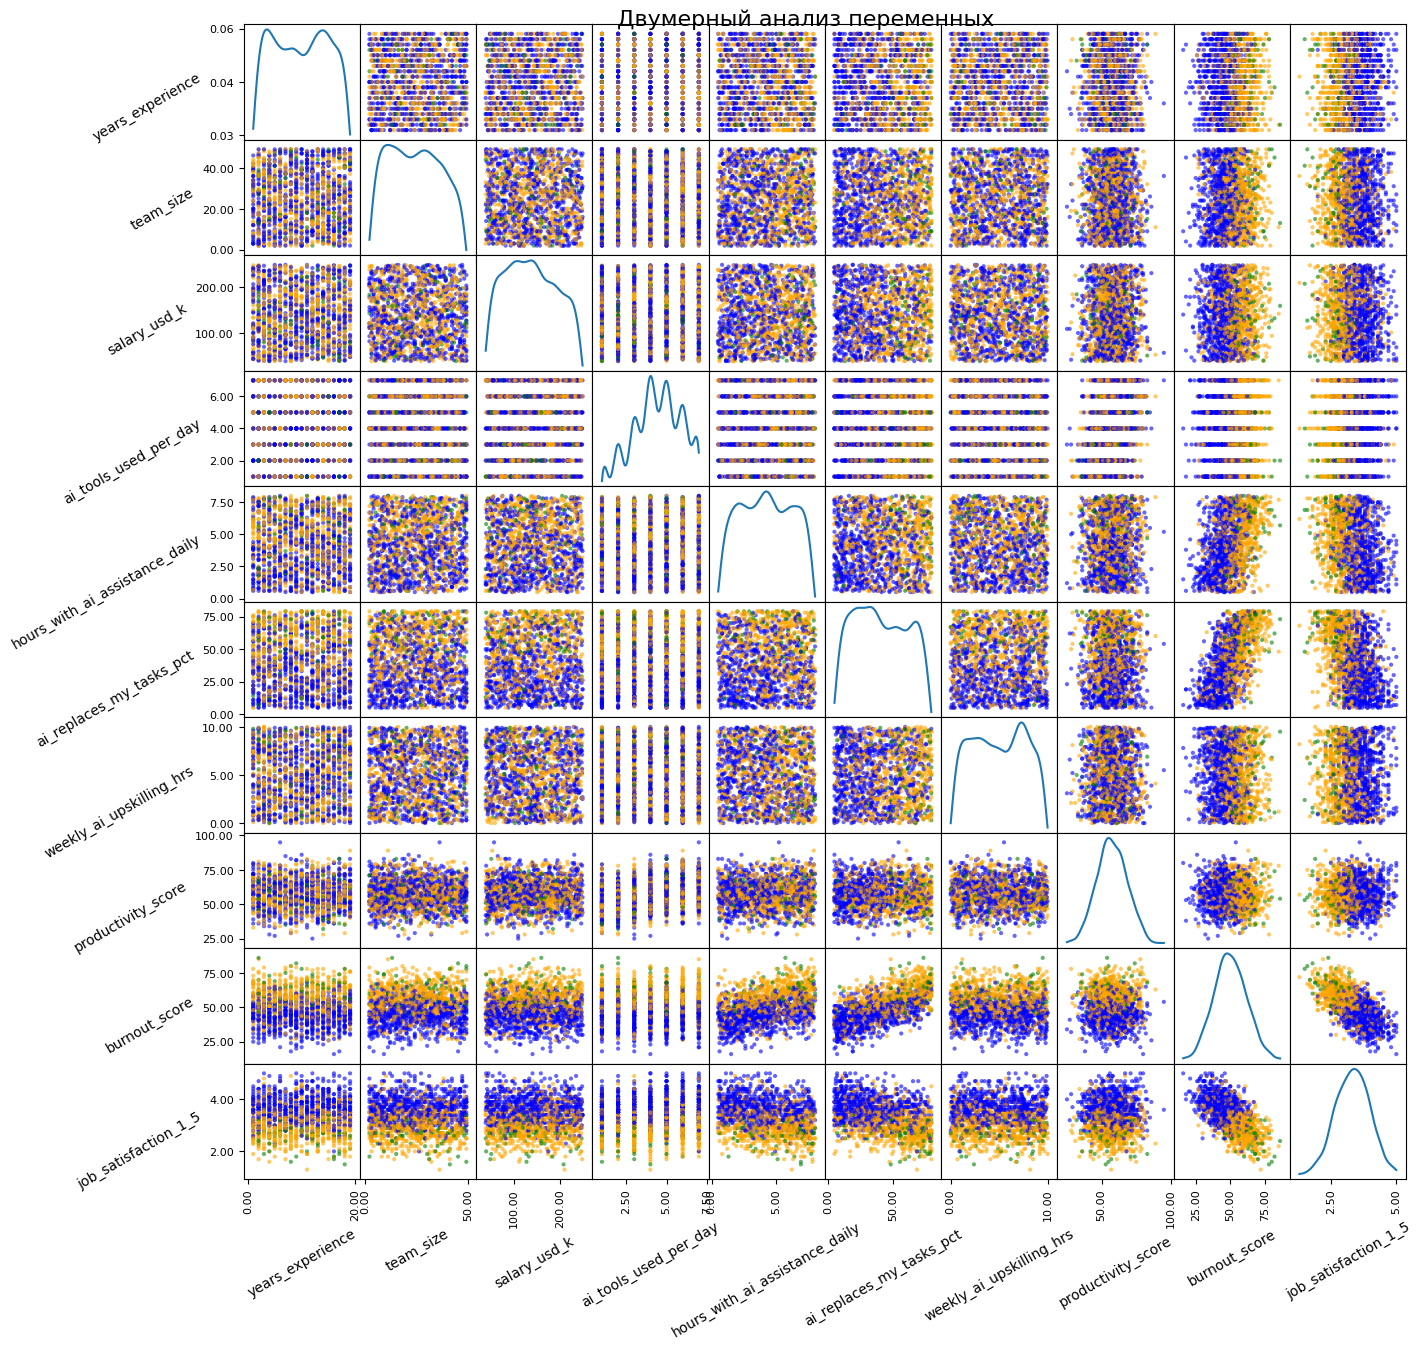

In [72]:
color_map = {
  'Low': 'blue',
  'Medium': 'orange',
  'High': 'green'
}

CLASS_COLORS = [color_map[x] for x in df[TARGET_FEATURE]] 

axes = scatter_matrix(df, alpha=.6, figsize=(15, 15), range_padding=.2, diagonal='kde', color=CLASS_COLORS)
plt.suptitle('Двумерный анализ переменных', fontsize=16, y=.89)

for ax in axes.flatten():
  ax.xaxis.label.set_rotation(30)
  ax.yaxis.label.set_rotation(30)
  ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
  ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
  ax.yaxis.label.set_ha('right')

* Можно заметить, что выводы из предыдущих анализов о __хороших предикатах__ (`burnout_score`, `job_satisfaction_1_5`) подтвердились: эти классы показывают относительно хорошую линейную разделимость в паре со всеми другими числовыми признаками. Хотя назвать хорошей линейной разделимостью это сложно - данные все равно сильно перемешаны, но хотя бы не так сильно, как у других признаков

* Остальные пары демонстрируют сильную перемешанность в диграммах рассеяния, что делает их бесполезными для линейных моделей.

*__Вывод:__ датасет показывает преимущественно сложные, нелинейные зависимости в данных*

In [73]:
# матрица корреляции намного симпатичнее выглядит в seaborn
def heatmap(df, ax, title):
  corr = df.corr()

  # пропустим пары со слабой корреляцией, попробуем поэкспериментировать с этой настройкой
  df_corr = corr[(corr>=.4) | (corr<=-.4)]

  # print(f'Empty columns: {get_empty_columns_names(df_corr)}')

  mask = np.triu(np.ones_like(corr))
  sns.heatmap(
    df_corr, 
    cbar=False, 
    mask=mask,
    ax=ax, 
    annot=True, 
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
  )

  ax.title.set_text(title)
  ax.tick_params(
    top=False,
    bottom=False,
    left=False,
    right=False,
  )

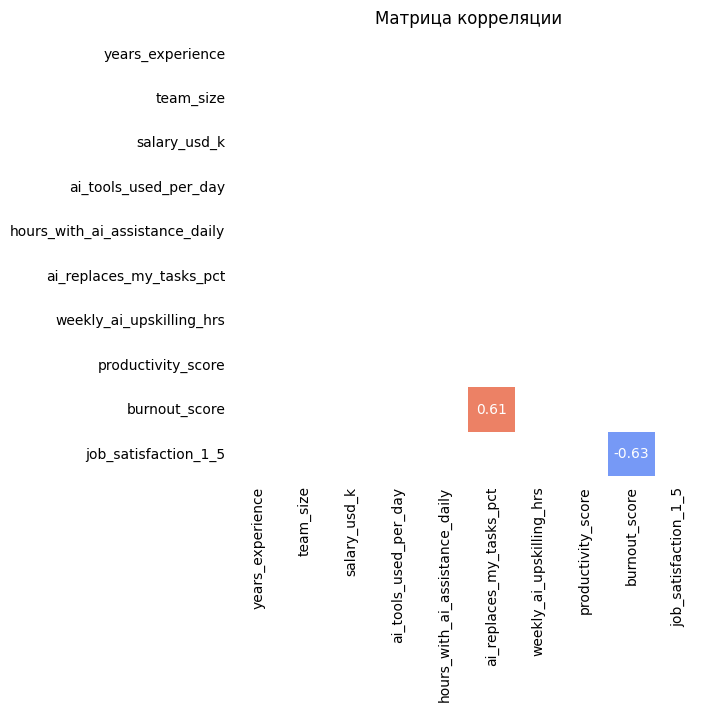

In [74]:
fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
hm = heatmap(df[NUMERIC_FEATURES], ax, 'Матрица корреляции')

Матрица корреляций практически пустая ↔ между большинством признаков нет линейной зависимости ↔ датасет показывает сложные, нелинейные взаимосвязи (как и отмечалось ранее).

* Признаки независимы друг от друга  (хорошо для обучения моделей, нет мультиколлинеарности).
* Простые линейные модели могут не найти закономерностей.
* `burnout_score` ↔ `ai_replaces_my_tasks_pct`: +0.61 (умеренная положительная корреляция) - Чем больше задач заменяет ИИ, тем выше уровень выгорания
* `job_satisfaction_1_5` ↔ `burnout_score`: -0.63 (умеренная отрицательная) - Чем выше выгорание, тем ниже удовлетворённость работой

Даже как-то неожиданно, что, например, `productivity_score` ни с чем не коррелирует (ни с выгоранием, ни с удовлетворённостью, ни с опытом)

## Многомерный анализ

В заключение, построим многомерную проекцию данных. Для этого применим преобразование PCA и посмотрим, даст ли нам что-то оно - например, сможем ли мы оценить хорошо ли разделимы данные с нормой и ненормой.

In [75]:
x = df[NUMERIC_FEATURES].values

# нормализуем значения
x = StandardScaler().fit_transform(x)

pca = PCA(n_components=3)
principalComponents = pca.fit_transform(x)
print(f'Explained variance: {pca.explained_variance_ratio_}\tSum: {pca.explained_variance_ratio_.sum()}')

Explained variance: [0.22371378 0.13288386 0.10473462]	Sum: 0.46133224701837444


__Вывод:__ низкая объяснённая дисперсия (46%) - три главные компоненты объясняют только 46.1% общей вариативности данных. При этом видно быстрое затухание важности компонент (вторая меньше первой на целых 9%, что и так почти 50% от первой компоненты)

Это говорит о том, что:
* Данные высокоразмерные и сложные, информация "размазана" по многим признакам
* Нет доминирующих направлений вариации (если бы первая компонента объясняла 60-70%, это означало бы наличие сильного скрытого фактора)
* Для сохранения 90%+ информации потребуются почти все исходные признаки

Положительные стороны в этом следующие:

* Все исходные признаки несут уникальную информацию → нет смысла удалять признаки на основе корреляции.
* Можно использовать все 10 признаков без риска мультиколлинеарности.

# Подведение итогов

По итогам анализа числовых признаков были получены следующие результаты:

* Датасет не содержит пропущенных (null) значений.
* Почти все числовые признаки имеют равномерное распределение (за исключением `productivity_score`, `burnout_score`, `job_satisfaction_1_5` - у них нормальное распределение)
* Данные почти не содержат выбросов. Наличие небольших выбросов было замечено лишь у признаков с нормальным распределением - что является нормой для такого распределения.
* Обнаржуен дисбаланс классов - класс `High` содержит значительно меньше данных. У оставшихся классов (`Low`, `Medium`) количетсво данных почти равное.
* Хорошие предикторы: `burnout_score`, `job_satisfaction_1_5`
* Все пары признаков показывают сложную линейную разделимость - относительно приемлимую раделимость показали, разве что пары с признаками `burnout_score`, `job_satisfaction_1_5`.
* Отсутствие мультиколлинеарности и низкая объяснённая дисперсия PCA (46% для 3 компонент).

Исходя из этого, могут быть сформулированы следующие выводы:
* __Данные сложные и нелинейные__.
* __Для решения задачи классфиикации нужны нелинейные модели:__ например, Random Forest или нейросети.
* __Ключевые драйверы оттока носят психоэмоциональный характер__ - признаки, связанные с организационной структурой (`years_experience`, `team_size`, `salary_usd_k`), оказались статистически шумными и не имеют предсказательной силы. В то же время, метрики состояния сотрудника (`burnout_score`, `job_satisfaction_1_5`) демонстрируют явное разделение классов. Это говорит о том, что риск увольнения в данной выборке определяется не внешними факторами (зарплата, стаж), а внутренним состоянием и удовлетворенностью.
* __Предиктивная сила скрыта в нелинейных комбинациях признаков:__ поскольку одномерные распределения классов схожи по форме, а двумерные проекции показывают лишь частичное разделение, решающие правила модели, скорее всего, будут представлять собой сложные нелинейные границы или взаимодействия нескольких признаков (например, «высокое выгорание» + «низкая удовлетворенность» + «средняя продуктивность»).

Рекоммендации:
* __Требуется работа с дисбалансом классов:__ 
    * Техники балансировки при обучении (например, `class_weight='balanced'` в моделях sklearn)
    * Методы семплирования: SMOTE (генерация синтетических примеров для класса High).
* __Приветствуется инженерия признаков (Feature Engineering):__ например, можно попробовать создать признаки-взаимодействия, особенно комбинируя ключевые предикторы:
    * `burnout_satisfaction_ratio` = `burnout_score` / `job_satisfaction_1_5`
    * `ai_stress_index` = `ai_replaces_my_tasks_pct` * `burnout_score`

*__Бизнес-рекомендация (гипотеза):__ Сфокусировать усилия по удержанию персонала не на повышении зарплат или изменении состава команд (так как эти признаки не коррелируют с риском), а на программах снижения выгорания, пересмотре нагрузки (автоматизация задач через ИИ должна контролироваться, чтобы не вызывать стресс) и повышении удовлетворенности работой.*